In [1]:
import pandas as pd
import numpy as np

pd.set_option("display.max_columns", None)

In [2]:
df = pd.read_csv("../data/raw/Data_for_UCI_named.csv")
print(df.shape)
df.head()

(10000, 14)


,tau1,tau2,tau3,tau4,p1,p2,p3,p4,g1,g2,g3,g4,stab,stabf
0,2.959060,3.079885,8.381025,9.780754,3.763085,-0.782604,-1.257395,-1.723086,0.650456,0.859578,0.887445,0.958034,0.055347,unstable
1,9.304097,4.902524,3.047541,1.369357,5.067812,-1.940058,-1.872742,-1.255012,0.413441,0.862414,0.562139,0.781760,-0.005957,stable
2,8.971707,8.848428,3.046479,1.214518,3.405158,-1.207456,-1.277210,-0.920492,0.163041,0.766689,0.839444,0.109853,0.003471,unstable
3,0.716415,7.669600,4.486641,2.340563,3.963791,-1.027473,-1.938944,-0.997374,0.446209,0.976744,0.929381,0.362718,0.028871,unstable
4,3.134112,7.608772,4.943759,9.857573,3.525811,-1.125531,-1.845975,-0.554305,0.797110,0.455450,0.656947,0.820923,0.049860,unstable


In [3]:
df.info()
print(df.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   tau1    10000 non-null  float64
 1   tau2    10000 non-null  float64
 2   tau3    10000 non-null  float64
 3   tau4    10000 non-null  float64
 4   p1      10000 non-null  float64
 5   p2      10000 non-null  float64
 6   p3      10000 non-null  float64
 7   p4      10000 non-null  float64
 8   g1      10000 non-null  float64
 9   g2      10000 non-null  float64
 10  g3      10000 non-null  float64
 11  g4      10000 non-null  float64
 12  stab    10000 non-null  float64
 13  stabf   10000 non-null  str    
dtypes: float64(13), str(1)
memory usage: 1.1 MB
tau1     0
tau2     0
tau3     0
tau4     0
p1       0
p2       0
p3       0
p4       0
g1       0
g2       0
g3       0
g4       0
stab     0
stabf    0
dtype: int64


In [4]:
print("Duplicate rows:", df.duplicated().sum())
print(df["stabf"].value_counts())
print(df["stabf"].value_counts(normalize=True))

Duplicate rows: 0
stabf
unstable    6380
stable      3620
Name: count, dtype: int64
stabf
unstable    0.638
stable      0.362
Name: proportion, dtype: float64


In [5]:
check = (df["p1"] - (df["p2"] + df["p3"] + df["p4"]).abs()).abs()
print("Max difference:", check.max())

Max difference: 6.217248937900877e-15


In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
tau1,10000.0,5.250000,2.742548,0.500793,2.874892,5.250004,7.624690,9.999469
tau2,10000.0,5.250001,2.742549,0.500141,2.875140,5.249981,7.624893,9.999837
tau3,10000.0,5.250004,2.742549,0.500788,2.875522,5.249979,7.624948,9.999450
tau4,10000.0,5.249997,2.742556,0.500473,2.874950,5.249734,7.624838,9.999443
p1,10000.0,3.750000,0.752160,1.582590,3.218300,3.751025,4.282420,5.864418
p2,10000.0,-1.250000,0.433035,-1.999891,-1.624901,-1.249966,-0.874977,-0.500108
p3,10000.0,-1.250000,0.433035,-1.999945,-1.625025,-1.249974,-0.875043,-0.500072
p4,10000.0,-1.250000,0.433035,-1.999926,-1.624960,-1.250007,-0.875065,-0.500025
g1,10000.0,0.525000,0.274256,0.050009,0.287521,0.525009,0.762435,0.999937
g2,10000.0,0.525000,0.274255,0.050053,0.287552,0.525003,0.762490,0.999944


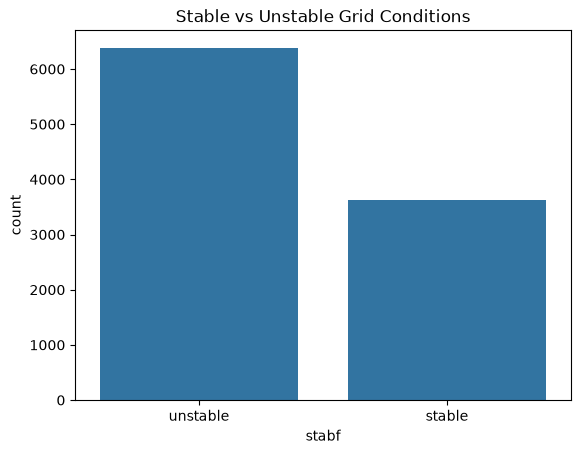

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x="stabf")
plt.title("Stable vs Unstable Grid Conditions")
plt.savefig("../reports/figures/class_counts.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
tau1,10000.0,5.250000,2.742548,0.500793,2.874892,5.250004,7.624690,9.999469
tau2,10000.0,5.250001,2.742549,0.500141,2.875140,5.249981,7.624893,9.999837
tau3,10000.0,5.250004,2.742549,0.500788,2.875522,5.249979,7.624948,9.999450
tau4,10000.0,5.249997,2.742556,0.500473,2.874950,5.249734,7.624838,9.999443
p1,10000.0,3.750000,0.752160,1.582590,3.218300,3.751025,4.282420,5.864418
p2,10000.0,-1.250000,0.433035,-1.999891,-1.624901,-1.249966,-0.874977,-0.500108
p3,10000.0,-1.250000,0.433035,-1.999945,-1.625025,-1.249974,-0.875043,-0.500072
p4,10000.0,-1.250000,0.433035,-1.999926,-1.624960,-1.250007,-0.875065,-0.500025
g1,10000.0,0.525000,0.274256,0.050009,0.287521,0.525009,0.762435,0.999937
g2,10000.0,0.525000,0.274255,0.050053,0.287552,0.525003,0.762490,0.999944


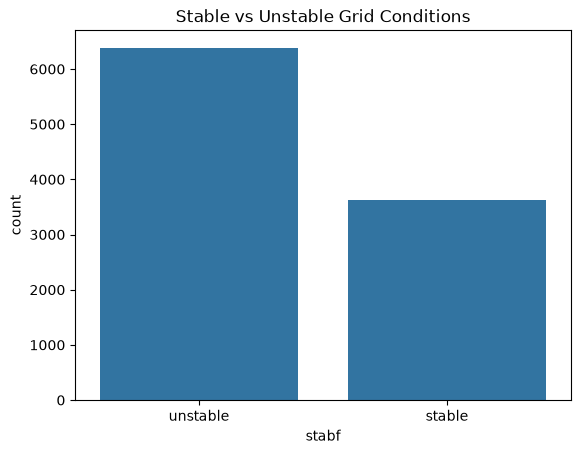

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x="stabf")
plt.title("Stable vs Unstable Grid Conditions")
plt.savefig("../reports/figures/class_counts.png", dpi=150, bbox_inches="tight")
plt.show()

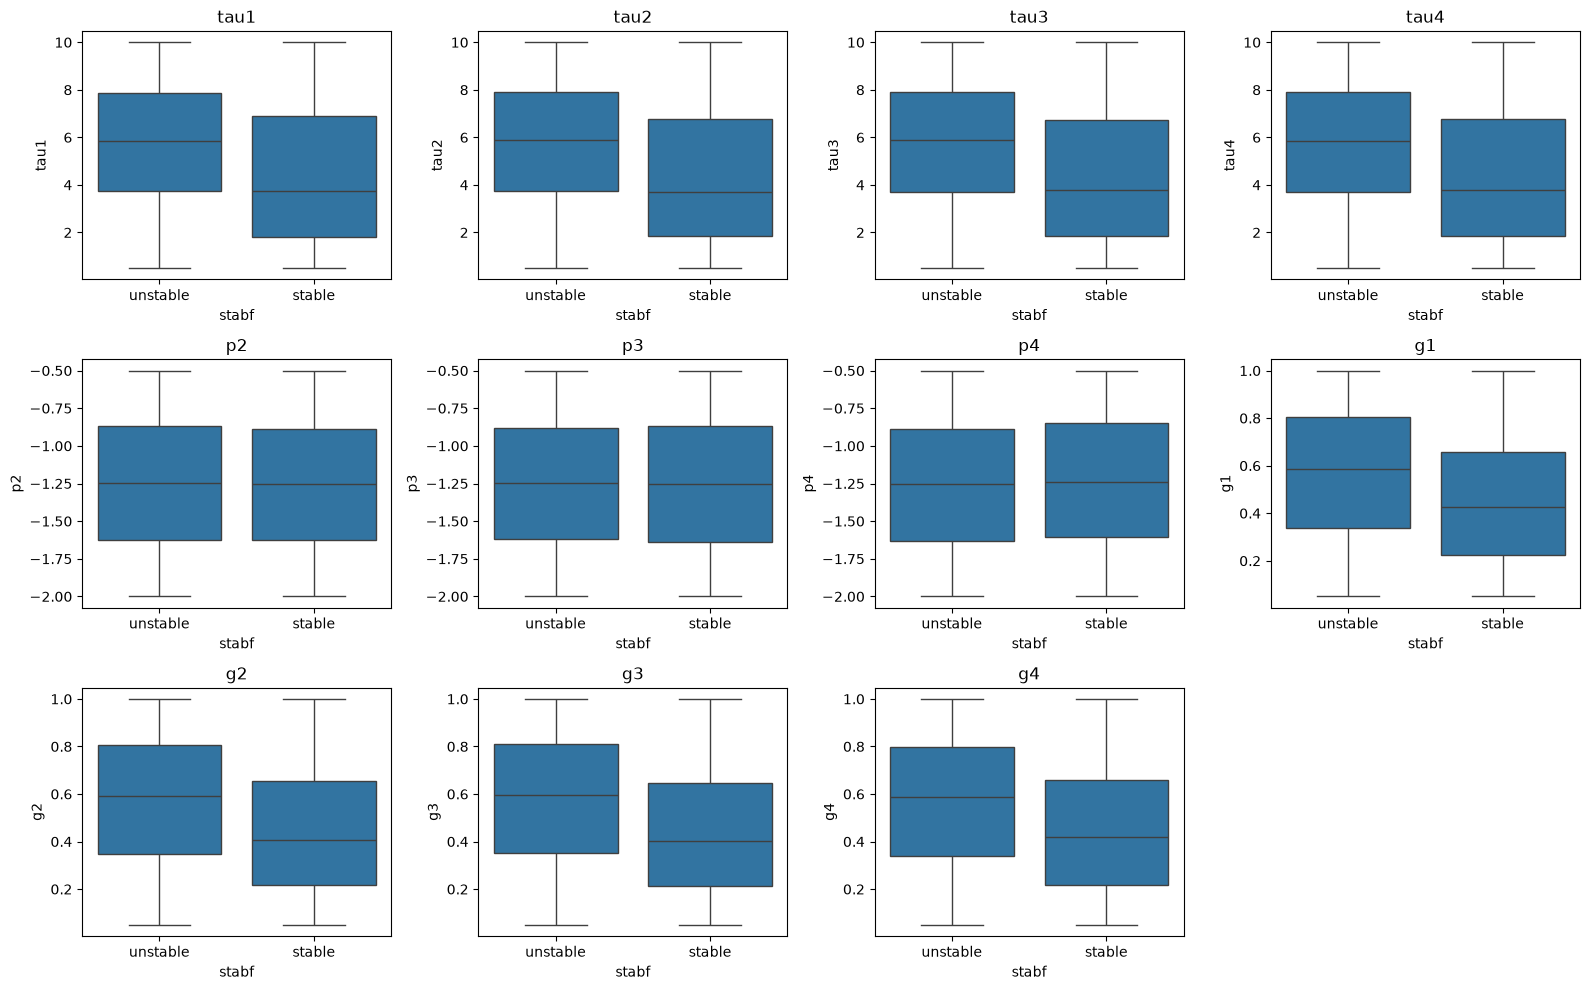

In [10]:
features = ["tau1", "tau2", "tau3", "tau4", "p2", "p3", "p4", "g1", "g2", "g3", "g4"]

fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.flat, features):
    sns.boxplot(data=df, x="stabf", y=col, ax=ax)
    ax.set_title(col)
axes.flat[-1].axis("off")
plt.tight_layout()
plt.savefig("../reports/figures/boxplots_by_stability.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
df.groupby("stabf")[features].mean().T

stabf,stable,unstable
tau1,4.394799,5.735239
tau2,4.353362,5.758752
tau3,4.385360,5.740601
tau4,4.378495,5.744485
p2,-1.253549,-1.247987
p3,-1.249626,-1.250212
p4,-1.236902,-1.257431
g1,0.453035,0.565832
g2,0.445872,0.569897
g3,0.440618,0.572879


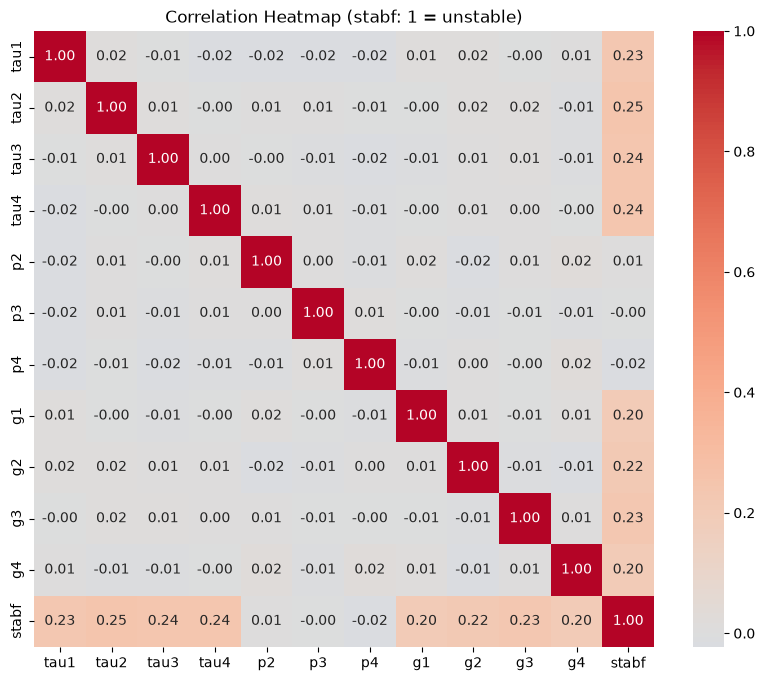

In [12]:
corr = df[features + ["stabf"]].assign(stabf=(df["stabf"] == "unstable").astype(int)).corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap (stabf: 1 = unstable)")
plt.savefig("../reports/figures/correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

In [13]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

df = pd.read_csv("../data/raw/Data_for_UCI_named.csv")

features = ["tau1", "tau2", "tau3", "tau4", "p2", "p3", "p4", "g1", "g2", "g3", "g4"]
X = df[features]
y = (df["stabf"] == "unstable").astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print(X_train.shape, X_test.shape)
print(y_train.mean(), y_test.mean())

(8000, 11) (2000, 11)
0.638 0.638


In [14]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score,
                             recall_score, f1_score, confusion_matrix)

log_reg = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(random_state=RANDOM_STATE, max_iter=1000)),
])

log_reg.fit(X_train, y_train)
pred = log_reg.predict(X_test)

print("Test accuracy :", accuracy_score(y_test, pred))
print("Precision (unstable):", precision_score(y_test, pred))
print("Recall (unstable)   :", recall_score(y_test, pred))
print("F1 (unstable)       :", f1_score(y_test, pred))
print(confusion_matrix(y_test, pred))

Test accuracy : 0.82
Precision (unstable): 0.8407738095238095
Recall (unstable)   : 0.8855799373040752
F1 (unstable)       : 0.8625954198473282
[[ 510  214]
 [ 146 1130]]


In [15]:
coefs = pd.Series(log_reg.named_steps["model"].coef_[0], index=features)
print(coefs.sort_values())

p4     -0.043503
p2      0.007524
p3      0.042891
g1      0.742518
g4      0.779722
g2      0.783437
tau1    0.838661
g3      0.845398
tau4    0.864361
tau3    0.869124
tau2    0.881552
dtype: float64


In [16]:
from sklearn.tree import DecisionTreeClassifier

def report(name, model, X_te, y_te):
    p = model.predict(X_te)
    print(name)
    print("  accuracy :", round(accuracy_score(y_te, p), 4))
    print("  precision:", round(precision_score(y_te, p), 4))
    print("  recall   :", round(recall_score(y_te, p), 4))
    print("  f1       :", round(f1_score(y_te, p), 4))
    print(confusion_matrix(y_te, p))

tree = DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, random_state=RANDOM_STATE)
tree.fit(X_train, y_train)

report("Decision Tree (max_depth=5), TEST", tree, X_test, y_test)
report("Decision Tree (max_depth=5), TRAIN", tree, X_train, y_train)

Decision Tree (max_depth=5), TEST
  accuracy : 0.792
  precision: 0.8219
  recall   : 0.8605
  f1       : 0.8407
[[ 486  238]
 [ 178 1098]]
Decision Tree (max_depth=5), TRAIN
  accuracy : 0.815
  precision: 0.8395
  recall   : 0.8779
  f1       : 0.8583
[[2039  857]
 [ 623 4481]]


In [17]:
from sklearn.ensemble import RandomForestClassifier

forest = RandomForestClassifier(
    n_estimators=200, min_samples_leaf=5, random_state=RANDOM_STATE, n_jobs=-1
)
forest.fit(X_train, y_train)

report("Random Forest, TEST", forest, X_test, y_test)
report("Random Forest, TRAIN", forest, X_train, y_train)

imp = pd.Series(forest.feature_importances_, index=features).sort_values(ascending=False)
print(imp)

Random Forest, TEST
  accuracy : 0.9285
  precision: 0.9282
  recall   : 0.9624
  f1       : 0.945
[[ 629   95]
 [  48 1228]]
Random Forest, TRAIN
  accuracy : 0.9909
  precision: 0.9897
  recall   : 0.9961
  f1       : 0.9929
[[2843   53]
 [  20 5084]]
tau2    0.135874
tau3    0.132200
tau1    0.131787
tau4    0.131207
g3      0.108863
g4      0.103136
g1      0.101641
g2      0.099914
p2      0.018806
p4      0.018586
p3      0.017986
dtype: float64


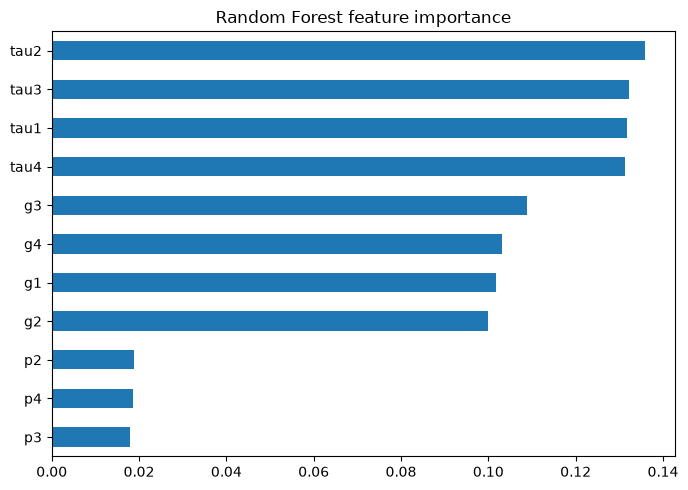

In [18]:
imp.sort_values().plot(kind="barh", figsize=(7, 5), title="Random Forest feature importance")
plt.tight_layout()
plt.savefig("../reports/figures/feature_importance.png", dpi=150)
plt.show()

                     Accuracy  Precision  Recall     F1
Logistic Regression     0.820      0.841   0.886  0.863
Decision Tree           0.792      0.822   0.861  0.841
Random Forest           0.928      0.928   0.962  0.945


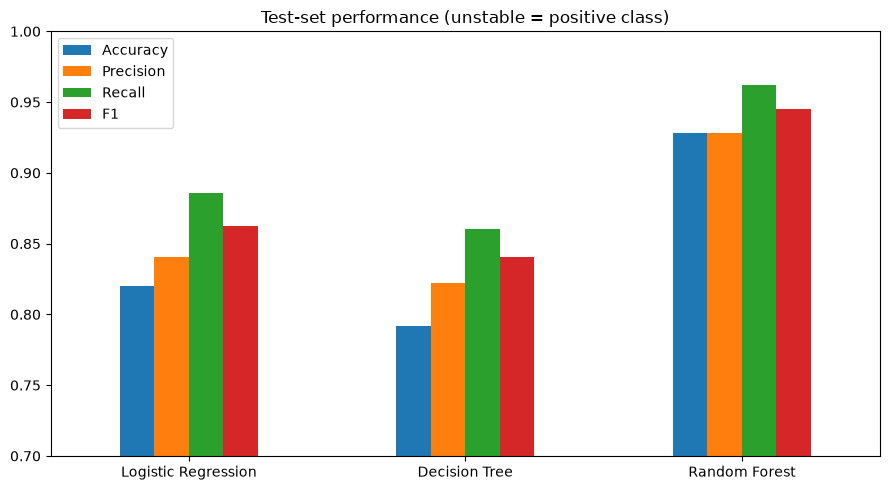

In [19]:
results = {}
for name, m in [("Logistic Regression", log_reg), ("Decision Tree", tree), ("Random Forest", forest)]:
    p = m.predict(X_test)
    results[name] = {
        "Accuracy": accuracy_score(y_test, p),
        "Precision": precision_score(y_test, p),
        "Recall": recall_score(y_test, p),
        "F1": f1_score(y_test, p),
    }

res = pd.DataFrame(results).T
print(res.round(3))

res.plot(kind="bar", figsize=(9, 5), ylim=(0.7, 1.0), title="Test-set performance (unstable = positive class)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("../reports/figures/model_comparison.png", dpi=150)
plt.show()

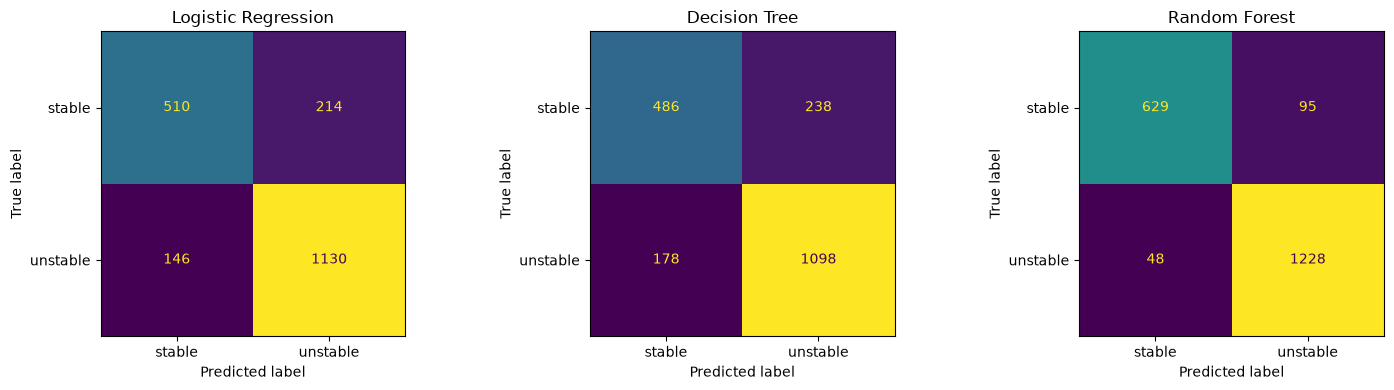

In [20]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, m) in zip(axes, [("Logistic Regression", log_reg),
                                ("Decision Tree", tree),
                                ("Random Forest", forest)]):
    ConfusionMatrixDisplay.from_estimator(
        m, X_test, y_test, display_labels=["stable", "unstable"], ax=ax, colorbar=False
    )
    ax.set_title(name)
plt.tight_layout()
plt.savefig("../reports/figures/confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

In [21]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = ["accuracy", "precision", "recall", "f1"]

cv_rows = {}
for name, m in [("Logistic Regression", log_reg),
                ("Decision Tree", tree),
                ("Random Forest", forest)]:
    scores = cross_validate(m, X_train, y_train, cv=cv, scoring=scoring)
    cv_rows[name] = {
        metric: f"{scores['test_' + metric].mean():.3f} ± {scores['test_' + metric].std():.3f}"
        for metric in scoring
    }

print(pd.DataFrame(cv_rows).T)

                          accuracy      precision         recall  \
Logistic Regression  0.815 ± 0.007  0.839 ± 0.006  0.878 ± 0.008   
Decision Tree        0.792 ± 0.012  0.803 ± 0.017  0.893 ± 0.021   
Random Forest        0.914 ± 0.008  0.913 ± 0.006  0.957 ± 0.007   

                                f1  
Logistic Regression  0.858 ± 0.006  
Decision Tree        0.845 ± 0.008  
Random Forest        0.935 ± 0.006  


In [22]:
from sklearn.model_selection import GridSearchCV

searches = {
    "Logistic Regression": GridSearchCV(
        log_reg, {"model__C": [0.01, 0.1, 1, 10, 100]},
        cv=cv, scoring="f1", n_jobs=-1),
    "Decision Tree": GridSearchCV(
        DecisionTreeClassifier(random_state=RANDOM_STATE),
        {"max_depth": [3, 5, 8, 12, None], "min_samples_leaf": [5, 20, 50]},
        cv=cv, scoring="f1", n_jobs=-1),
    "Random Forest": GridSearchCV(
        RandomForestClassifier(random_state=RANDOM_STATE),
        {"n_estimators": [200, 400], "max_depth": [None, 10, 20], "min_samples_leaf": [1, 2, 5]},
        cv=cv, scoring="f1", n_jobs=-1),
}

for name, s in searches.items():
    s.fit(X_train, y_train)
    print(name, "| best CV F1:", round(s.best_score_, 3), "|", s.best_params_)

Logistic Regression | best CV F1: 0.858 | {'model__C': 0.1}
Decision Tree | best CV F1: 0.878 | {'max_depth': 12, 'min_samples_leaf': 20}
Random Forest | best CV F1: 0.938 | {'max_depth': None, 'min_samples_leaf': 2, 'n_estimators': 400}


In [ ]:
tuned = {name: s.best_estimator_ for name, s in searches.items()}

rows = {}
for name, m in tuned.items():
    p = m.predict(X_test)
    rows[name] = {
        "Accuracy": accuracy_score(y_test, p),
        "Precision": precision_score(y_test, p),
        "Recall": recall_score(y_test, p),
        "F1": f1_score(y_test, p),
        "Missed unstable (FN)": confusion_matrix(y_test, p)[1, 0],
    }

print(pd.DataFrame(rows).T.round(3))

                     Accuracy  Precision  Recall     F1  Missed unstable (FN)
Logistic Regression     0.820      0.840   0.886  0.862                 145.0
Decision Tree           0.852      0.875   0.897  0.886                 132.0
Random Forest           0.930      0.931   0.961  0.946                  50.0


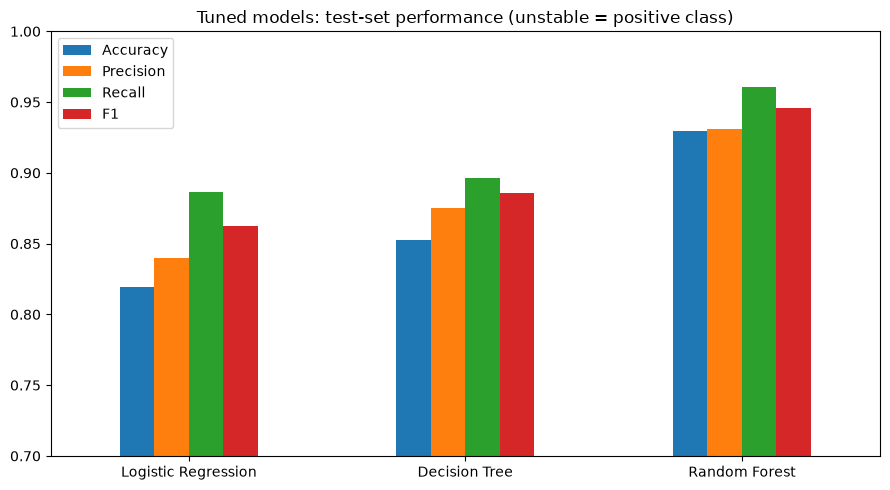

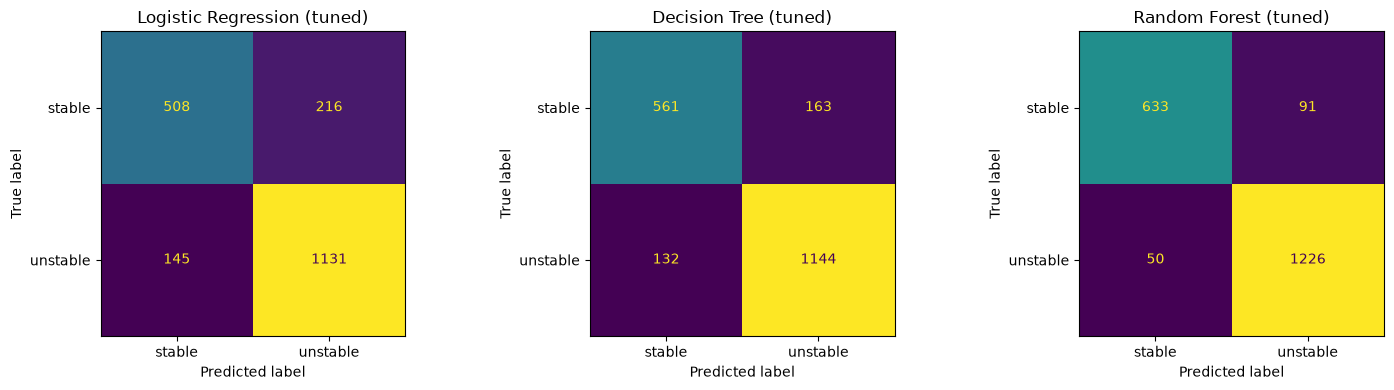

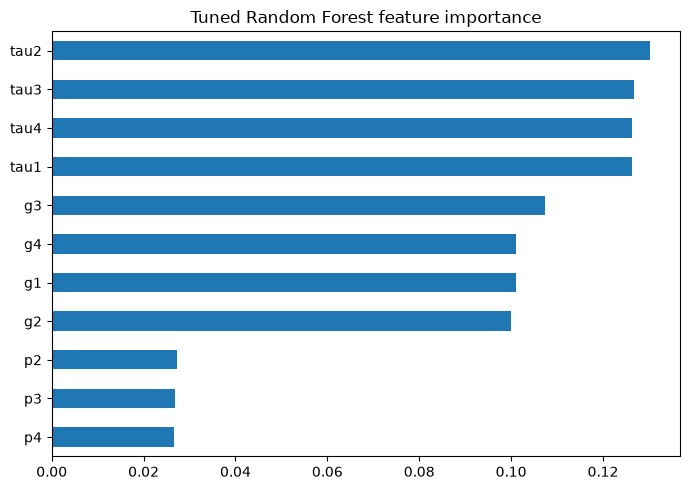

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# 1) Metric comparison, tuned models, test set
res_t = {}
for name, m in tuned.items():
    p = m.predict(X_test)
    res_t[name] = {
        "Accuracy": accuracy_score(y_test, p),
        "Precision": precision_score(y_test, p),
        "Recall": recall_score(y_test, p),
        "F1": f1_score(y_test, p),
    }
res_t = pd.DataFrame(res_t).T
res_t.plot(kind="bar", figsize=(9, 5), ylim=(0.7, 1.0),
           title="Tuned models: test-set performance (unstable = positive class)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("../reports/figures/model_comparison_tuned.png", dpi=150)
plt.show()

# 2) Confusion matrices, tuned models
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, m) in zip(axes, tuned.items()):
    ConfusionMatrixDisplay.from_estimator(
        m, X_test, y_test, display_labels=["stable", "unstable"], ax=ax, colorbar=False)
    ax.set_title(name + " (tuned)")
plt.tight_layout()
plt.savefig("../reports/figures/confusion_matrices_tuned.png", dpi=150, bbox_inches="tight")
plt.show()

# 3) Feature importance, tuned Random Forest
imp_t = pd.Series(tuned["Random Forest"].feature_importances_, index=features).sort_values()
imp_t.plot(kind="barh", figsize=(7, 5), title="Tuned Random Forest feature importance")
plt.tight_layout()
plt.savefig("../reports/figures/feature_importance_tuned.png", dpi=150)
plt.show()

In [ ]:
import sys
sys.path.append("..")
from src.data_processing import load_raw, make_xy, split_data

df2 = load_raw()
X2, y2 = make_xy(df2)
X_tr2, X_te2, y_tr2, y_te2 = split_data(X2, y2)

print(X_tr2.shape, X_te2.shape, y_tr2.mean(), y_te2.mean())
print("Same test rows as before:", (X_te2.index == X_test.index).all())

(8000, 11) (2000, 11) 0.638 0.638
Same test rows as before: True


In [ ]:
%load_ext autoreload
%autoreload 2

from src.train import build_models
from src.evaluate import evaluate

models = build_models(tuned=True)
for m in models.values():
    m.fit(X_tr2, y_tr2)

print(evaluate(models, X_te2, y_te2).round(3))

                     Accuracy  Precision  Recall     F1     TN     FP     FN  \
Logistic Regression     0.820      0.840   0.886  0.862  508.0  216.0  145.0   
Decision Tree           0.852      0.875   0.897  0.886  561.0  163.0  132.0   
Random Forest           0.930      0.931   0.961  0.946  633.0   91.0   50.0   

                         TP  
Logistic Regression  1131.0  
Decision Tree        1144.0  
Random Forest        1226.0  
